# VehiDE — полигоны из VIA JSON

`0Train_via_annos.json` и `0Val_via_annos.json` содержат записи `name` и `regions`: координаты `all_x` / `all_y` и строковый `class`. Фото лежат в `image/image/` и `validation/validation/`.

Сохраняются исходные имена семи классов: `mat_bo_phan`, `rach`, `mop_lom`, `tray_son`, `vo_kinh`, `thung`, `be_den`. Числовые ID классов в разметке отсутствуют.

`SPLIT`: `train`, `val`, `all`. Пример: `CLASS_FILTER = "tray_son"`.

Запустите ячейки сверху вниз. **Для новой случайной подборки повторите последнюю ячейку.** Настройки: количество фото, выборка, фильтр класса, случайное зерно, контуры, рамки и подписи. Исходные поля выбранной записи: `selected_samples[0]["metadata"]`.


In [1]:
import csv
import json
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта с каталогом datasets/.")
VIEWERS_DIR = PROJECT_ROOT / "code" / "viewers"
if str(VIEWERS_DIR) not in sys.path:
    sys.path.insert(0, str(VIEWERS_DIR))

from viewer_common import (
    IMAGE_SUFFIXES, image_files, load_coco, load_supervisely,
    read_jsonl, show_samples, summarize,
)


In [2]:
DATASET_ROOT = PROJECT_ROOT / "datasets" / "vehide"
SPLIT = "train"
N_IMAGES = 6
N_COLS = 3
SEED = None                 # Целое число фиксирует подборку
CLASS_FILTER = None         # Название класса или список; None = все
SHOW_MASKS = True
SHOW_BOXES = True
SHOW_LABELS = True
SHOW_CLASS_IDS = False
ONLY_ANNOTATED = False


In [3]:
def load_dataset(root):
    samples = []
    sources = {
        "train": ("0Train_via_annos.json", root / "image" / "image"),
        "val": ("0Val_via_annos.json", root / "validation" / "validation"),
    }
    for split_name, (annotation_name, image_directory) in sources.items():
        entries = json.loads((root / annotation_name).read_text(encoding="utf-8"))
        for key, entry in entries.items():
            filename = entry.get("name") or key
            annotations = []
            for region in entry.get("regions", []):
                xs, ys = region["all_x"], region["all_y"]
                if len(xs) != len(ys) or len(xs) < 3:
                    raise ValueError(f"Некорректный полигон: {filename}")
                annotations.append({
                    "label": region["class"],
                    "polygons": [list(map(list, zip(xs, ys)))],
                    "raw": region,
                })
            samples.append({
                "image_path": image_directory / filename, "file_name": filename,
                "split": split_name, "annotations": annotations,
                "metadata": entry, "task": "segmentation",
            })
    return samples

dataset = load_dataset(DATASET_ROOT)
summary = summarize(dataset)


Записей: 13,945; изображения отсутствуют: 0
Выборки: {'train': 11621, 'val': 2324}
Классы (число меток):
  be_den: 2,782
  mat_bo_phan: 2,818
  mop_lom: 5,681
  rach: 5,509
  thung: 2,423
  tray_son: 14,647
  vo_kinh: 2,221


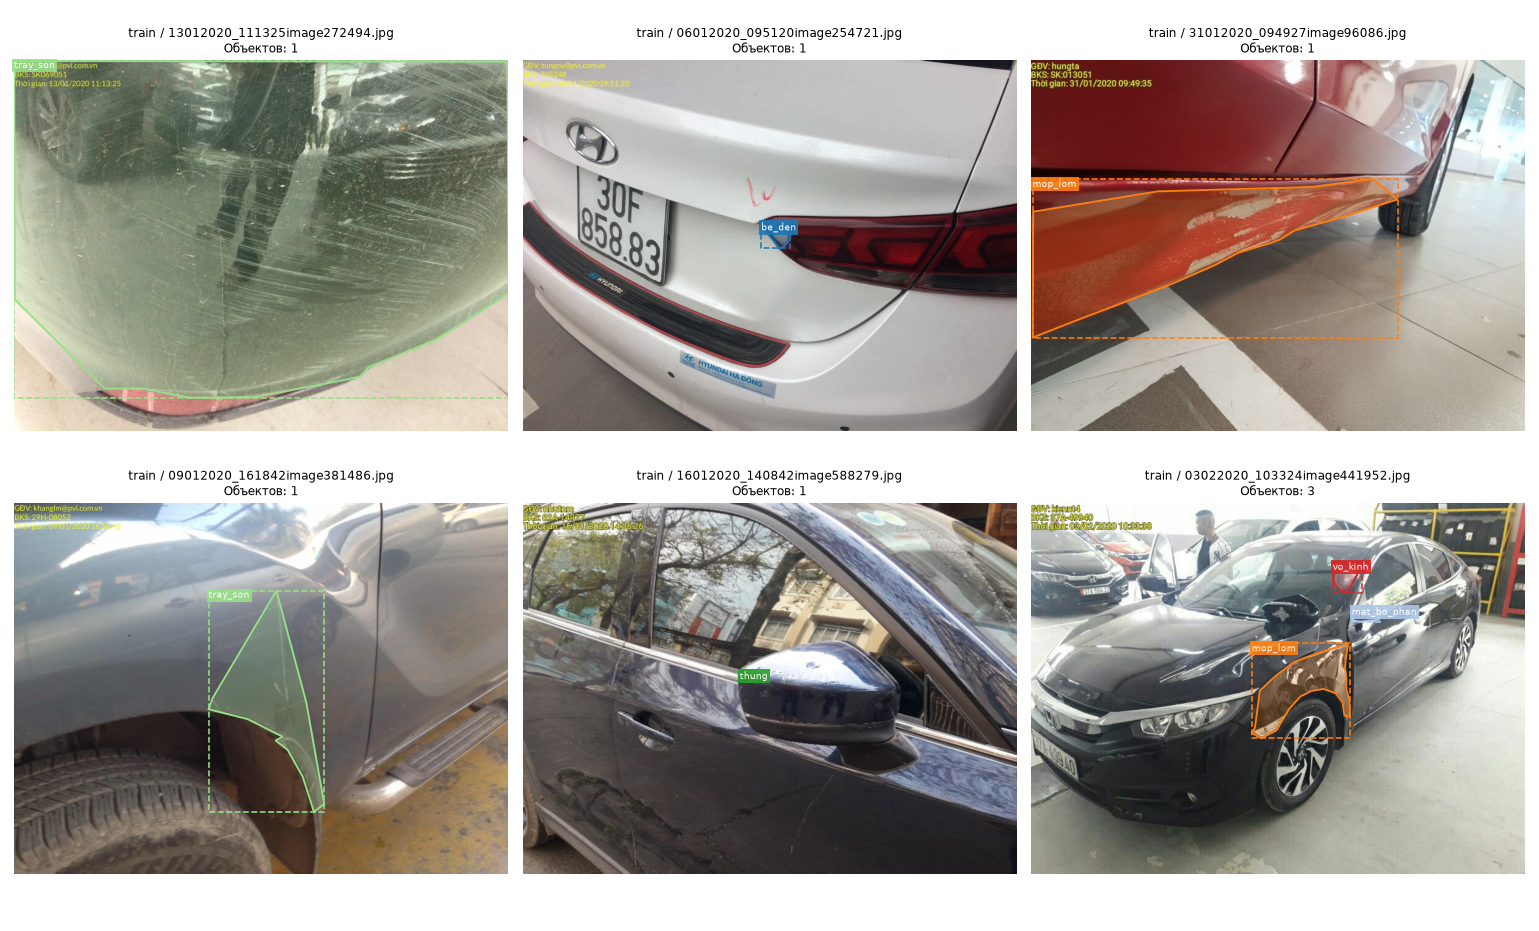

In [4]:
# Повторный запуск этой ячейки показывает новую случайную подборку.
figure, selected_samples = show_samples(
    dataset, n_images=N_IMAGES, n_cols=N_COLS, seed=SEED,
    split=SPLIT, class_filter=CLASS_FILTER,
    show_masks=SHOW_MASKS, show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS, show_class_ids=SHOW_CLASS_IDS,
    only_annotated=ONLY_ANNOTATED,
)
